<a href="https://colab.research.google.com/github/alexisdanielrodriguezdiaz2a-lgtm/Detective-de-senales/blob/main/Codigo_Detective_de_Senales.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

=== 1.1 y 1.2: Entorno configurado y parámetros establecidos ===
Frecuencia de muestreo (fs): 10000 Hz
Frecuencia portadora (fc): 1000 Hz
Tasa de símbolos (Rs): 100 Baud

=== 1.3: Funciones generadoras de ASK, FSK, PSK y 16-QAM creadas con éxito ===
=== 1.5: Función de Ruido AWGN programada ===
Generando 1000 muestras por cada una de las 4 clases...

=== 1.4: Dataset generado correctamente ===
Dimensiones de la matriz de datos (X_data): (4000, 5000)
Dimensiones de las etiquetas (y_data): (4000,)

=== 1.6: Datos divididos (80% / 20%) ===
Muestras de Entrenamiento: 3200
Muestras de Prueba: 800


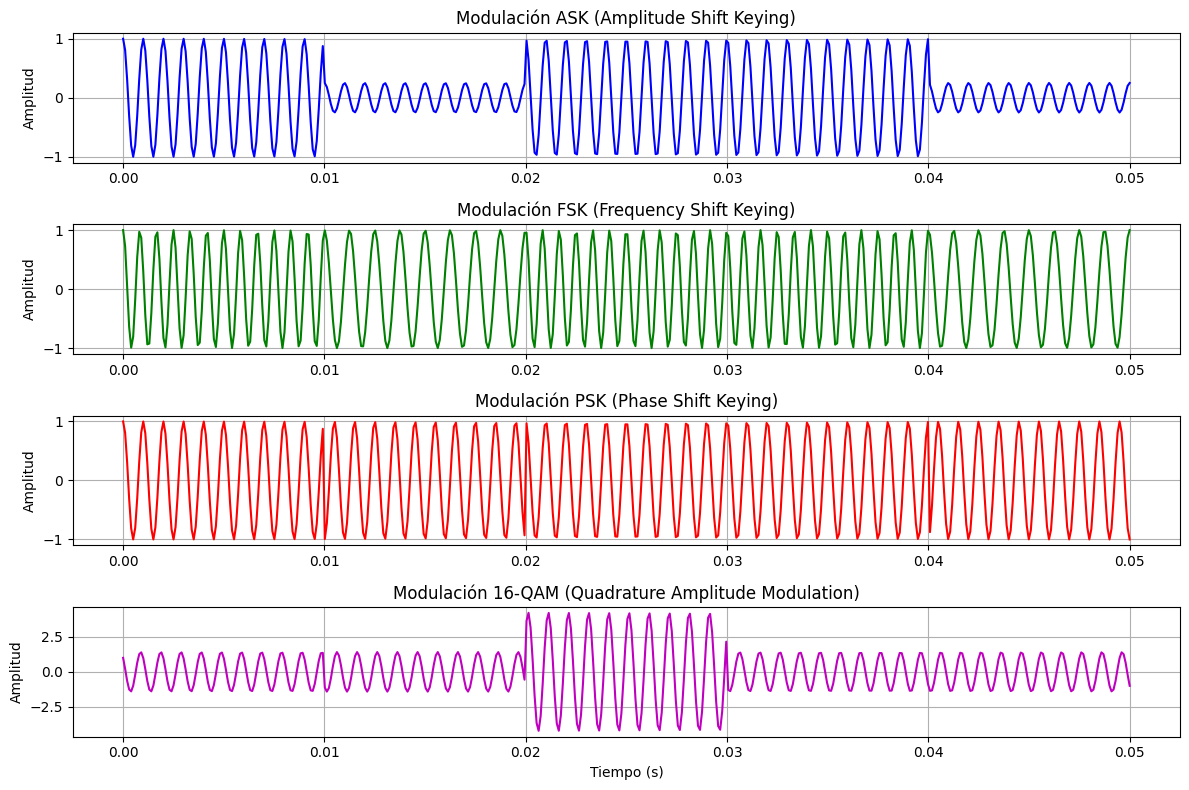

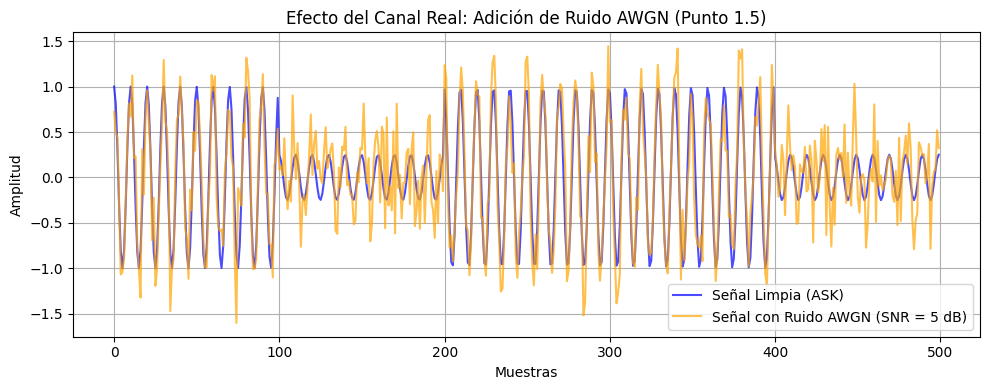

In [1]:
# ==========================================
# FASE 1: Generación y Preparación de Datos
# Proyecto: "El Detective de Señales"
# ALEXIS Daniel Rodriguez DIAZ

import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# ------------------------------------------
# 1.1 & 1.2: Configuración y Parámetros de la Señal
# ------------------------------------------
np.random.seed(42)  # Para reproducibilidad

fs = 10000       # Frecuencia de muestreo (Hz)
fc = 1000        # Frecuencia portadora (Hz)
Rs = 100         # Tasa de símbolos (baudios / símbolos por segundo)
T_symbol = 1.0 / Rs
samples_per_symbol = int(fs / Rs)

num_symbols = 50 # Símbolos por muestra para la visualización
t = np.linspace(0, num_symbols * T_symbol, num_symbols * samples_per_symbol)

print("=== 1.1 y 1.2: Entorno configurado y parámetros establecidos ===")
print(f"Frecuencia de muestreo (fs): {fs} Hz")
print(f"Frecuencia portadora (fc): {fc} Hz")
print(f"Tasa de símbolos (Rs): {Rs} Baud\n")

# ------------------------------------------
# 1.3: Programar los Generadores de Señales
# ------------------------------------------
def generar_ask(bits, t, fc, samples_per_symbol):
    signal = np.zeros_codes = len(bits) * samples_per_symbol
    signal = np.zeros(len(t))
    carrier = np.cos(2 * np.pi * fc * t)
    for i, bit in enumerate(bits):
        start = i * samples_per_symbol
        end = (i + 1) * samples_per_symbol
        amplitude = 1.0 if bit == 1 else 0.25 # ASK con dos niveles
        signal[start:end] = amplitude * carrier[start:end]
    return signal

def generar_fsk(bits, t, fc, samples_per_symbol, f_dev=200):
    signal = np.zeros(len(t))
    for i, bit in enumerate(bits):
        start = i * samples_per_symbol
        end = (i + 1) * samples_per_symbol
        freq = fc + f_dev if bit == 1 else fc - f_dev
        signal[start:end] = np.cos(2 * np.pi * freq * t[start:end])
    return signal

def generar_psk(bits, t, fc, samples_per_symbol):
    signal = np.zeros(len(t))
    for i, bit in enumerate(bits):
        start = i * samples_per_symbol
        end = (i + 1) * samples_per_symbol
        phase = 0.0 if bit == 1 else np.pi # BPSK
        signal[start:end] = np.cos(2 * np.pi * fc * t[start:end] + phase)
    return signal

def generar_16qam(simbolos_qam, t, fc, samples_per_symbol):
    signal = np.zeros(len(t))
    for i, (i_val, q_val) in enumerate(simbolos_qam):
        start = i * samples_per_symbol
        end = (i + 1) * samples_per_symbol
        signal[start:end] = (i_val * np.cos(2 * np.pi * fc * t[start:end]) -
                             q_val * np.sin(2 * np.pi * fc * t[start:end]))
    return signal

print("=== 1.3: Funciones generadoras de ASK, FSK, PSK y 16-QAM creadas con éxito ===")

# ------------------------------------------
# 1.5: Función para añadir Ruido AWGN
# ------------------------------------------
def agregar_awgn(signal, snr_db):
    signal_power = np.mean(signal ** 2)
    snr_linear = 10 ** (snr_db / 10.0)
    noise_power = signal_power / snr_linear
    noise = np.sqrt(noise_power) * np.random.normal(0, 1, len(signal))
    return signal + noise

print("=== 1.5: Función de Ruido AWGN programada ===")

# ------------------------------------------
# 1.4: Generar el Conjunto de Datos (Dataset)
# ------------------------------------------
num_muestras_por_clase = 1000 # 1,000 muestras por cada tipo de modulación
clases = ['ASK', 'FSK', 'PSK', '16QAM']

X_data = []
y_data = []

print(f"Generando {num_muestras_por_clase} muestras por cada una de las {len(clases)} clases...")

for clase in clases:
    for _ in range(num_muestras_por_clase):
        bits = np.random.randint(0, 2, num_symbols)

        if clase == 'ASK':
            sig = generar_ask(bits, t, fc, samples_per_symbol)
        elif clase == 'FSK':
            sig = generar_fsk(bits, t, fc, samples_per_symbol)
        elif clase == 'PSK':
            sig = generar_psk(bits, t, fc, samples_per_symbol)
        elif clase == '16QAM':
            # Generar símbolos aleatorios para 16-QAM (niveles en I y Q: -3, -1, 1, 3)
            niveles = [-3, -1, 1, 3]
            sims = [(np.random.choice(niveles), np.random.choice(niveles)) for _ in range(num_symbols)]
            sig = generar_16qam(sims, t, fc, samples_per_symbol)

        # Añadir ruido aleatorio (SNR entre 0 dB y 20 dB para simular canal real)
        snr_aleatorio = np.random.uniform(0, 20)
        sig_ruidosa = agregar_awgn(sig, snr_aleatorio)

        X_data.append(sig_ruidosa)
        y_data.append(clase)

X_data = np.array(X_data)
y_data = np.array(y_data)

print(f"\n=== 1.4: Dataset generado correctamente ===")
print(f"Dimensiones de la matriz de datos (X_data): {X_data.shape}")
print(f"Dimensiones de las etiquetas (y_data): {y_data.shape}")

# ------------------------------------------
# 1.6: Separación de Datos (Entrenamiento y Prueba)
# ------------------------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X_data, y_data, test_size=0.20, random_state=42, stratify=y_data
)

print(f"\n=== 1.6: Datos divididos (80% / 20%) ===")
print(f"Muestras de Entrenamiento: {X_train.shape[0]}")
print(f"Muestras de Prueba: {X_test.shape[0]}")

# ------------------------------------------
# Visualización de Evidencia (Gráficas para Captura)
# ------------------------------------------
plt.figure(figsize=(12, 8))

# Generar una señal limpia de ejemplo para graficar
t_plot = np.linspace(0, 5 * T_symbol, 5 * samples_per_symbol)
bits_ej = np.array([1, 0, 1, 1, 0])

plt.subplot(4, 1, 1)
plt.plot(t_plot, generar_ask(bits_ej, t_plot, fc, samples_per_symbol), color='b')
plt.title("Modulación ASK (Amplitude Shift Keying)")
plt.ylabel("Amplitud")
plt.grid(True)

plt.subplot(4, 1, 2)
plt.plot(t_plot, generar_fsk(bits_ej, t_plot, fc, samples_per_symbol), color='g')
plt.title("Modulación FSK (Frequency Shift Keying)")
plt.ylabel("Amplitud")
plt.grid(True)

plt.subplot(4, 1, 3)
plt.plot(t_plot, generar_psk(bits_ej, t_plot, fc, samples_per_symbol), color='r')
plt.title("Modulación PSK (Phase Shift Keying)")
plt.ylabel("Amplitud")
plt.grid(True)

plt.subplot(4, 1, 4)
sims_ej = [(np.random.choice([-3, -1, 1, 3]), np.random.choice([-3, -1, 1, 3])) for _ in range(5)]
plt.plot(t_plot, generar_16qam(sims_ej, t_plot, fc, samples_per_symbol), color='m')
plt.title("Modulación 16-QAM (Quadrature Amplitude Modulation)")
plt.xlabel("Tiempo (s)")
plt.ylabel("Amplitud")
plt.grid(True)

plt.tight_layout()
plt.show()

# Gráfica adicional con ruido AWGN (1.5)
plt.figure(figsize=(10, 4))
sig_limpia = generar_ask(np.array([1, 0, 1, 1, 0, 1, 0, 1]), t_plot, fc, samples_per_symbol)
sig_ruido = agregar_awgn(sig_limpia, snr_db=5) # SNR de 5 dB (ruido alto)
plt.plot(sig_limpia, label="Señal Limpia (ASK)", color='blue', alpha=0.7)
plt.plot(sig_ruido, label="Señal con Ruido AWGN (SNR = 5 dB)", color='orange', alpha=0.7)
plt.title("Efecto del Canal Real: Adición de Ruido AWGN (Punto 1.5)")
plt.xlabel("Muestras")
plt.ylabel("Amplitud")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Clases codificadas: {np.str_('16QAM'): np.int64(0), np.str_('ASK'): np.int64(1), np.str_('FSK'): np.int64(2), np.str_('PSK'): np.int64(3)}
Forma de entrada para la red: (3200, 5000, 1)

=== 2.2: Arquitectura del Modelo Diseñada ===


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 5000, 32)       │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 1250, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 1250, 64)       │        10,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 312, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 19968)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     1,278,016 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,288,836 (4.92 MB)

 Trainable params: 1,288,836 (4.92 MB)

 Non-trainable params: 0 (0.00 B)


=== 2.3: Modelo compilado con Adam y Categorical Crossentropy ===

=== 2.4: Iniciando entrenamiento ===
Epoch 1/15
100/100 ━━━━━━━━━━━━━━━━━━━━ 23s 217ms/step - accuracy: 0.5838 - loss: 0.8663 - val_accuracy: 0.7500 - val_loss: 0.3860
Epoch 2/15
100/100 ━━━━━━━━━━━━━━━━━━━━ 41s 220ms/step - accuracy: 0.8259 - loss: 0.3751 - val_accuracy: 1.0000 - val_loss: 0.1683
Epoch 3/15
100/100 ━━━━━━━━━━━━━━━━━━━━ 40s 213ms/step - accuracy: 0.9087 - loss: 0.2261 - val_accuracy: 1.0000 - val_loss: 0.0507
Epoch 4/15
100/100 ━━━━━━━━━━━━━━━━━━━━ 42s 219ms/step - accuracy: 0.8953 - loss: 0.2085 - val_accuracy: 1.0000 - val_loss: 0.0722
Epoch 5/15
100/100 ━━━━━━━━━━━━━━━━━━━━ 21s 207ms/step - accuracy: 0.8859 - loss: 0.2075 - val_accuracy: 1.0000 - val_loss: 0.0457
Epoch 6/15
100/100 ━━━━━━━━━━━━━━━━━━━━ 21s 210ms/step - accuracy: 0.8853 - loss: 0.1902 - val_accuracy: 1.0000 - val_loss: 0.0653
Epoch 7/15
100/100 ━━━━━━━━━━━━━━━━━━━━ 21s 213ms/step - accuracy: 0.8922 - loss: 0.1798 - val_accuracy: 1.00

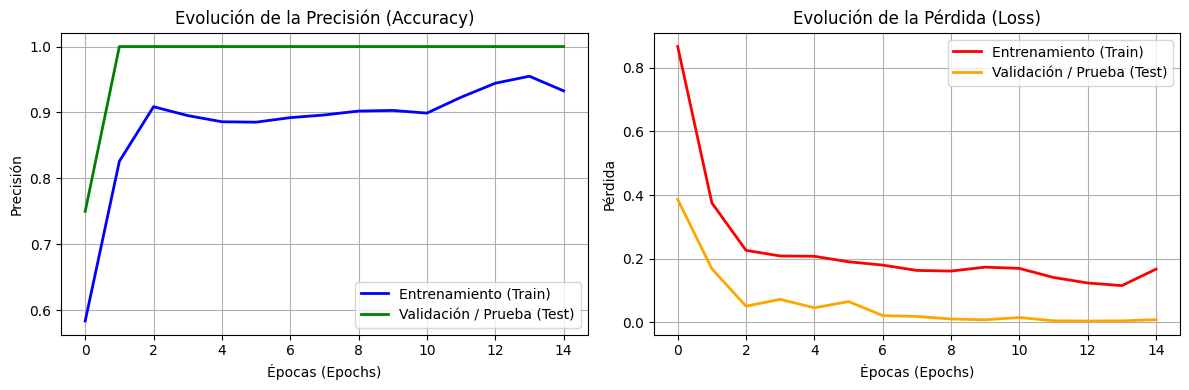

In [2]:
# ==========================================
# FASE 2: Diseño y Entrenamiento del Modelo
# Proyecto: "El Detective de Señales"
# ==========================================

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Conv1D, MaxPooling1D, Flatten, Dense, Dropout
from tensorflow.keras.utils import to_categorical
from sklearn.preprocessing import LabelEncoder

# ------------------------------------------
# Preparación de datos para la CNN 1D
# ------------------------------------------
# 1. Codificar etiquetas de texto ('ASK', 'FSK', etc.) a formato One-Hot
encoder = LabelEncoder()
y_train_num = encoder.fit_transform(y_train)
y_test_num = encoder.transform(y_test)

y_train_cat = to_categorical(y_train_num, num_classes=4)
y_test_cat = to_categorical(y_test_num, num_classes=4)

# 2. Redimensionar X para Conv1D: (muestras, longitud_señal, 1 canal)
X_train_cnn = X_train.reshape((X_train.shape[0], X_train.shape[1], 1))
X_test_cnn = X_test.reshape((X_test.shape[0], X_test.shape[1], 1))

print("Clases codificadas:", dict(zip(encoder.classes_, encoder.transform(encoder.classes_))))
print(f"Forma de entrada para la red: {X_train_cnn.shape}\n")

# ------------------------------------------
# 2.2. Diseñar el modelo (Arquitectura CNN 1D)
# ------------------------------------------
modelo = Sequential([
    # Capa de entrada con la longitud de la señal (5000 muestras, 1 canal)
    Input(shape=(X_train_cnn.shape[1], 1)),

    # Primera capa convolucional + reducción de dimensionalidad
    Conv1D(filters=32, kernel_size=7, activation='relu', padding='same'),
    MaxPooling1D(pool_size=4),

    # Segunda capa convolucional + reducción de dimensionalidad
    Conv1D(filters=64, kernel_size=5, activation='relu', padding='same'),
    MaxPooling1D(pool_size=4),

    # Aplanamiento (Flatten) para conectar con capas densas
    Flatten(),
    Dense(64, activation='relu'),
    Dropout(0.3), # Evita el sobreajuste (overfitting)

    # Capa de salida Densa con 4 neuronas (una por cada modulación) y Softmax
    Dense(4, activation='softmax')
])

print("=== 2.2: Arquitectura del Modelo Diseñada ===")
modelo.summary()

# ------------------------------------------
# 2.3. Compilar el modelo
# ------------------------------------------
modelo.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)
print("\n=== 2.3: Modelo compilado con Adam y Categorical Crossentropy ===")

# ------------------------------------------
# 2.4. Entrenar el modelo (.fit)
# ------------------------------------------
print("\n=== 2.4: Iniciando entrenamiento ===")
historial = modelo.fit(
    X_train_cnn, y_train_cat,
    epochs=15,               # Número de pasadas completas por el dataset
    batch_size=32,           # Muestras procesadas antes de actualizar pesos
    validation_data=(X_test_cnn, y_test_cat),
    verbose=1
)

# ------------------------------------------
# 2.5. Guardar el modelo entrenado
# ------------------------------------------
nombre_archivo = "modelo_detective_senales.keras"
modelo.save(nombre_archivo)
print(f"\n=== 2.5: Modelo exportado y guardado exitosamente como '{nombre_archivo}' ===")

# ------------------------------------------
# Gráficas de Evidencia (Precisión y Pérdida)
# ------------------------------------------
plt.figure(figsize=(12, 4))

# Gráfica 1: Precisión (Accuracy)
plt.subplot(1, 2, 1)
plt.plot(historial.history['accuracy'], label='Entrenamiento (Train)', color='blue', linewidth=2)
plt.plot(historial.history['val_accuracy'], label='Validación / Prueba (Test)', color='green', linewidth=2)
plt.title('Evolución de la Precisión (Accuracy)')
plt.xlabel('Épocas (Epochs)')
plt.ylabel('Precisión')
plt.legend()
plt.grid(True)

# Gráfica 2: Pérdida (Loss)
plt.subplot(1, 2, 2)
plt.plot(historial.history['loss'], label='Entrenamiento (Train)', color='red', linewidth=2)
plt.plot(historial.history['val_loss'], label='Validación / Prueba (Test)', color='orange', linewidth=2)
plt.title('Evolución de la Pérdida (Loss)')
plt.xlabel('Épocas (Epochs)')
plt.ylabel('Pérdida')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

=== Modelo 'modelo_detective_senales.keras' cargado correctamente ===


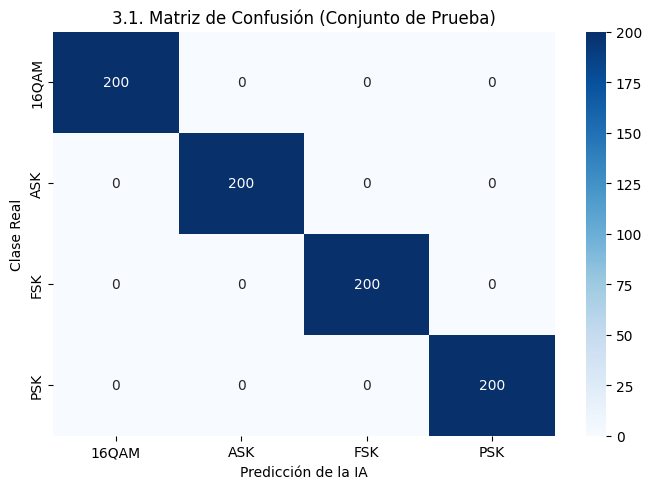


=== Reporte de Clasificación por Modulación (3.1 y 3.4) ===
              precision    recall  f1-score   support

       16QAM     1.0000    1.0000    1.0000       200
         ASK     1.0000    1.0000    1.0000       200
         FSK     1.0000    1.0000    1.0000       200
         PSK     1.0000    1.0000    1.0000       200

    accuracy                         1.0000       800
   macro avg     1.0000    1.0000    1.0000       800
weighted avg     1.0000    1.0000    1.0000       800


=== 3.2. Resultados de Prueba de Estrés por Nivel de SNR ===
SNR = -10 dB (SNR Bajo (Mucho ruido)): Precisión = 50.00%
SNR =  -5 dB (SNR Bajo (Mucho ruido)): Precisión = 70.88%
SNR =   0 dB (SNR Bajo (Mucho ruido)): Precisión = 100.00%
SNR =   5 dB (SNR Medio): Precisión = 100.00%
SNR =  10 dB (SNR Medio): Precisión = 100.00%
SNR =  15 dB (SNR Alto (Poco ruido)): Precisión = 100.00%
SNR =  20 dB (SNR Alto (Poco ruido)): Precisión = 100.00%


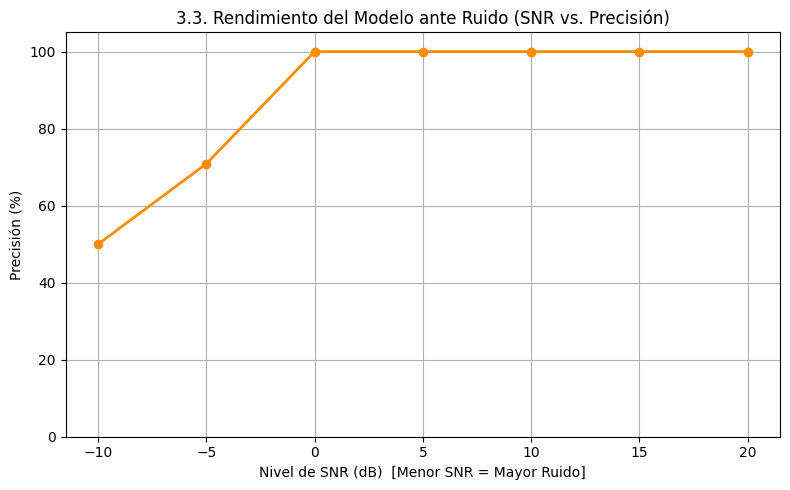

In [3]:
# ==========================================
# FASE 3: Evaluación y Robustez
# Proyecto: "El Detective de Señales"
# ==========================================

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report
from tensorflow.keras.models import load_model
from tensorflow.keras.utils import to_categorical
from sklearn.preprocessing import LabelEncoder

# Cargar el modelo guardado en la Fase 2
modelo_cargado = load_model("modelo_detective_senales.keras")
print("=== Modelo 'modelo_detective_senales.keras' cargado correctamente ===")

# Asegurar codificación y formato de entrada para X_test
clases = ['16QAM', 'ASK', 'FSK', 'PSK']
encoder = LabelEncoder()
encoder.fit(clases)

y_test_num = encoder.transform(y_test)
y_test_cat = to_categorical(y_test_num, num_classes=4)
X_test_cnn = X_test.reshape((X_test.shape[0], X_test.shape[1], 1))

# ------------------------------------------
# 3.1. Matriz de Confusión y Reporte
# ------------------------------------------
predicciones_prob = modelo_cargado.predict(X_test_cnn, verbose=0)
y_pred_num = np.argmax(predicciones_prob, axis=1)

cm = confusion_matrix(y_test_num, y_pred_num)

plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=encoder.classes_,
            yticklabels=encoder.classes_)
plt.title('3.1. Matriz de Confusión (Conjunto de Prueba)')
plt.xlabel('Predicción de la IA')
plt.ylabel('Clase Real')
plt.tight_layout()
plt.show()

print("\n=== Reporte de Clasificación por Modulación (3.1 y 3.4) ===")
print(classification_report(y_test_num, y_pred_num, target_names=encoder.classes_, digits=4))

# ------------------------------------------
# 3.2 y 3.3. Prueba de Estrés (SNR) y Gráfica de Rendimiento
# ------------------------------------------
# Definimos niveles de SNR de bajo (mucho ruido) a alto (poco ruido)
niveles_snr = [-10, -5, 0, 5, 10, 15, 20]
precisiones_snr = []

# Generamos señales limpias de prueba por clase para evaluar cada SNR de forma controlada
num_eval_por_clase = 200
T_symbol = 1.0 / Rs
samples_per_symbol = int(fs / Rs)
num_symbols = 50
t_eval = np.linspace(0, num_symbols * T_symbol, num_symbols * samples_per_symbol)

X_limpias = []
y_limpias = []

for clase_real in ['ASK', 'FSK', 'PSK', '16QAM']:
    for _ in range(num_eval_por_clase):
        if clase_real == 'ASK':
            bits = np.random.randint(0, 2, num_symbols)
            sig = generar_ask(bits, t_eval, fc, samples_per_symbol)
        elif clase_real == 'FSK':
            bits = np.random.randint(0, 2, num_symbols)
            sig = generar_fsk(bits, t_eval, fc, samples_per_symbol)
        elif clase_real == 'PSK':
            bits = np.random.randint(0, 2, num_symbols)
            sig = generar_psk(bits, t_eval, fc, samples_per_symbol)
        elif clase_real == '16QAM':
            niveles = [-3, -1, 1, 3]
            sims = [(np.random.choice(niveles), np.random.choice(niveles)) for _ in range(num_symbols)]
            sig = generar_16qam(sims, t_eval, fc, samples_per_symbol)
        X_limpias.append(sig)
        y_limpias.append(clase_real)

X_limpias = np.array(X_limpias)
y_limpias_num = encoder.transform(np.array(y_limpias))
y_limpias_cat = to_categorical(y_limpias_num, num_classes=4)

print("\n=== 3.2. Resultados de Prueba de Estrés por Nivel de SNR ===")
for snr in niveles_snr:
    X_snr = np.array([agregar_awgn(s, snr) for s in X_limpias])
    X_snr_cnn = X_snr.reshape((X_snr.shape[0], X_snr.shape[1], 1))
    _, acc = modelo_cargado.evaluate(X_snr_cnn, y_limpias_cat, verbose=0)
    precisiones_snr.append(acc * 100)
    etiqueta_ruido = "SNR Bajo (Mucho ruido)" if snr <= 0 else ("SNR Medio" if snr <= 10 else "SNR Alto (Poco ruido)")
    print(f"SNR = {snr:3d} dB ({etiqueta_ruido}): Precisión = {acc*100:.2f}%")

# 3.3. Gráfica de Rendimiento: SNR vs Precisión
plt.figure(figsize=(8, 5))
plt.plot(niveles_snr, precisiones_snr, marker='o', linewidth=2, color='darkorange')
plt.title('3.3. Rendimiento del Modelo ante Ruido (SNR vs. Precisión)')
plt.xlabel('Nivel de SNR (dB)  [Menor SNR = Mayor Ruido]')
plt.ylabel('Precisión (%)')
plt.ylim(0, 105)
plt.grid(True)
plt.tight_layout()
plt.show()